# DL / CARN · Local Course 1 recap
A compact companion for the published first course and laboratory. Runs on CPU without downloads or GPU-specific cells.

## Goal
Track tensor dimensions, distinguish gradients from updates, and run a complete miniature training loop. Preview convolution output shapes before later architecture seminars.

## Setup
Use the repository environment in `../SETUP.md`. Synthetic data only. This supplements the linked Hub notebooks and does not replace their exercises or homework.

In [1]:
import sys
import torch
import torchvision
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
torch.set_num_threads(1)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 12})
print("Python", sys.version.split()[0], "torch", torch.__version__, "torchvision", torchvision.__version__)
print("This notebook uses CPU. Available accelerators:", "CUDA", torch.cuda.is_available(), "MPS", torch.backends.mps.is_available())

Python 3.13.5 torch 2.14.1 torchvision 0.29.1
This notebook uses CPU. Available accelerators: CUDA False MPS True


## Steps
### 1. Batches, features, and Linear
A `Linear(3, 2)` layer stores weights of shape `(2, 3)`. It applies `X @ weight.T + bias` to a row batch. Predict the shape before running.

In [2]:
X = torch.arange(12, dtype=torch.float32).reshape(4, 3)
layer = nn.Linear(3, 2)
out = layer(X)
assert out.shape == (4, 2)
assert torch.allclose(out, X @ layer.weight.T + layer.bias)
print("Input", tuple(X.shape), "weights", tuple(layer.weight.shape), "output", tuple(out.shape))
print("Mean per feature", X.mean(dim=0))
print("Mean per example", X.mean(dim=1))

Input (4, 3) weights (2, 3) output (4, 2)
Mean per feature tensor([4.5000, 5.5000, 6.5000])
Mean per example tensor([ 1.,  4.,  7., 10.])


### 2. A derivative is not an update
For `loss=(w*x-target)^2`, the chain rule gives `d(loss)/dw = 2*(w*x-target)*x`. `backward()` accumulates that derivative in `.grad`. It does not change `w`.

In [3]:
w = torch.tensor(2., requires_grad=True)
x = torch.tensor(3.)
target = torch.tensor(1.)
loss = (w*x-target)**2
loss.backward()
assert w.item() == 2.
assert w.grad.item() == 30.
print("Before update: w=", w.item(), "gradient=", w.grad.item())
with torch.no_grad():
    w -= .01*w.grad
assert torch.isclose(w, torch.tensor(1.7))
w.grad = None
print("After explicit update: w=", w.item())

Before update: w= 2.0 gradient= 30.0
After explicit update: w= 1.7000000476837158


### 3. A complete classification loop
We generate two Gaussian clusters with a fixed seed. Use integer class indices with `CrossEntropyLoss`; feed it raw logits, without an extra softmax.

Training examples update parameters. Validation examples below illustrate a separate evaluation pass. We do not tune on this validation set or claim a real-world benchmark.

In [4]:
generator = torch.Generator().manual_seed(42)
def make_data(n):
    features = torch.randn(n, 2, generator=generator) * .35
    labels = torch.arange(n) % 2
    features[:, 0] += (2*labels-1).float()
    return features, labels.long()
train_X, train_y = make_data(64)
val_X, val_y = make_data(64)
loader = DataLoader(TensorDataset(train_X, train_y), batch_size=16, shuffle=True,
                    generator=torch.Generator().manual_seed(123), num_workers=0)
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 2))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=.1)
losses = []
model.train()
for epoch in range(30):
    total_loss = 0.
    for features, labels in loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(features)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()*len(labels)
    losses.append(total_loss/len(train_y))
model.eval()
with torch.no_grad():
    val_accuracy = (model(val_X).argmax(dim=1) == val_y).float().mean().item()
assert losses[-1] < losses[0]
assert torch.isfinite(torch.tensor(losses)).all()
print(f"Training loss {losses[0]:.4f} -> {losses[-1]:.4f}")
print(f"Synthetic validation accuracy: {val_accuracy:.1%}")

Training loss 0.5581 -> 0.0474
Synthetic validation accuracy: 100.0%


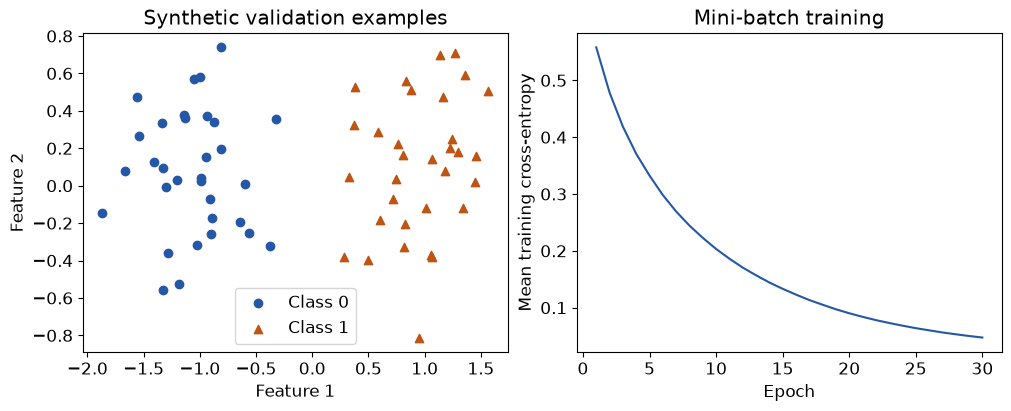

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for label, marker, color in [(0, "o", "#2458a6"), (1, "^", "#be5514")]:
    mask = val_y == label
    axes[0].scatter(val_X[mask, 0], val_X[mask, 1], marker=marker, color=color, label=f"Class {label}")
axes[0].set(title="Synthetic validation examples", xlabel="Feature 1", ylabel="Feature 2")
axes[0].legend()
axes[1].plot(range(1, len(losses)+1), losses, color="#2458a6")
axes[1].set(title="Mini-batch training", xlabel="Epoch", ylabel="Mean training cross-entropy")
plt.show()

### 4. Convolutions preserve the batch dimension
PyTorch Conv2d normally expects `(batch, channels, height, width)`. For kernel 3, stride 1, padding 1 and dilation 1, spatial size stays the same. Max pooling with kernel/stride 2 halves these even spatial dimensions.

In [6]:
images = torch.randn(2, 3, 16, 16)
conv = nn.Conv2d(3, 8, kernel_size=3, padding=1)
features = conv(images)
pooled = nn.MaxPool2d(2)(features)
assert features.shape == (2, 8, 16, 16)
assert pooled.shape == (2, 8, 8, 8)
assert sum(p.numel() for p in conv.parameters()) == 8*3*3*3+8
print("Images", tuple(images.shape), "features", tuple(features.shape), "pooled", tuple(pooled.shape))
print("Convolution parameters (including biases):", sum(p.numel() for p in conv.parameters()))

Images (2, 3, 16, 16) features (2, 8, 16, 16) pooled (2, 8, 8, 8)
Convolution parameters (including biases): 224


## Checks
1. What happens if you remove `zero_grad`? Gradients accumulate across backward calls.
2. What happens if you remove `optimizer.step`? Gradients may be computed, but parameters do not learn.
3. Why is `model.eval()` different from `torch.no_grad()`? The former changes behaviour of modules such as dropout/batch normalization; the latter controls gradient recording.
4. How many weights and biases does `Linear(3,2)` have? Six weights and two biases.
5. Does a high score on a tiny synthetic dataset establish performance on real data? No.

## Next Steps
Follow the [published Lab 1](https://github.com/Tensor-Reloaded/Deep-Learning-and-Generative-AI-2026/tree/main/Lab01) for the actual homework and the Hub tensor exercises. CUDA-specific benchmarking and compilation sections need a compatible environment. Several advanced cells allocate large arrays; run selected examples rather than blindly running every upstream cell.

Sources: [Course 1](https://sites.google.com/view/rbenchea/deep-learning-generative-ai), [PyTorch autograd](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html), [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html). Prepared 2 October 2026.